In [1]:
from src.parametric_estimation import ParametricEstimation
from src.motivating_example import MotivatingExample
from src.ampute_mar import AmputeMAR
from src.data_generator import DataGenerator

import numpy as np
import pandas as pd
import torch

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_squared_error

from collections.abc import Callable
from typing import Optional

from joblib import Parallel, delayed

import nlopt

During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 


### Choose parameters

In [18]:
n = 20
d = 10
eps = 1e-2
methods = ['generation', 'imputation', 'complete', 'complete-case', 'nmmipw', 'gmm_ipw']
motexp = False
Ycol = 0 # may be "new" if use_motexp=False

### PARAMS FOR OTHER DISTRIBUTIONS
if not motexp:
    data_generator = DataGenerator(distr='Logistic')
    n_pat = 5

### Set up classes

In [19]:
class DataGeneratorXY():
    def __init__(
        self,
        coef_true: torch.tensor,
        sample_error: Callable[[int], torch.tensor],
        data_generator_X: DataGenerator
    ):
        self.sample_X = data_generator_X.sample_truth
        self.sample_error = sample_error
        self.coef_true = coef_true

    def sample_truth(
        self,
        n:int,
        d:int
    ):
        # generate X based on DataGenerator
        X = self.sample_X(n, d-1)
        # generate Y as linear combination + error
        Y = self.coef_true[0] + X @ self.coef_true[1:] + self.sample_error(n)
        # concatenate X and Y
        # (Y in first column because ampute function keeps last column fully observed)
        return torch.cat([Y[:, None], X], dim=1)

class XYM_gen():
    def __init__(
        self,
        n,
        d,
        data_generator,
        n_pat
    ):
        self.data_generator = data_generator
        self.amputemar = AmputeMAR(n, d, n_pat, seed=1)

    def get_X(self):
        return self.data_generator.sample_truth(n, d)

    def get_M(self, X):
        _, M = self.amputemar.ampute(X)
        return M
        

In [20]:
if motexp:
    XM_generator = MotivatingExample(type='mar', n=n, d=d)
    coef_true = torch.tensor([0, 0.7] + [0]*(d-2))
else:
    # create a new column for Y which really follows a linear regression of the other variables
    if Ycol == "new":
        coef_true = torch.tensor(np.random.choice([0, 0.5, -0.5, 2, -2], size=d)) #d-1 + intercept
        dg = DataGeneratorXY(coef_true=coef_true, sample_error=lambda n: np.sqrt(0.5)*torch.randn(n), data_generator_X=data_generator)
        Ycol = 0
    # otherwise we regress one of the X columns (Ycol) given all others 
    elif type(Ycol) == int and Ycol in np.arange(-d, d):
        coef_true = None
        dg = data_generator
    else:
        raise ValueError("Ycol needs to be set to 'new' or an integer between -d (counting backwards) and d")

    XM_generator = XYM_gen(n, d, dg, n_pat)
        

### Run experiments

In [21]:
def job(
        XM_generator,
        eps: float = None, # clamping scale
        Ycol:int = None, # which variable
        methods: list = None
    ):
    X = XM_generator.get_X()
    M = XM_generator.get_M(X)
    pe = ParametricEstimation(X=X, M=M)

    # generate test data to compute regression accuracy
    test_data = XM_generator.get_X()
    Xtest = test_data[:, np.arange(test_data.shape[1]) != Ycol % test_data.shape[1]]
    Ytest = test_data[:, Ycol]

    out = {}
    for method in methods:
        lin_reg = pe.linear_regression(Ycol=Ycol, method=method, eps=eps)
        coef = np.concatenate(([lin_reg.intercept_], lin_reg.coef_))
        err = mean_squared_error(lin_reg.predict(Xtest), Ytest)
        out[method] = (coef, err)
    return out

In [22]:
B = 2 # CHANGE

results = Parallel(n_jobs=-1)(
    delayed(job)(
        XM_generator=XM_generator,
        eps=eps,
        Ycol=Ycol,
        methods=methods
    )
    for _ in range(B)
)
    
coef_est = {m: [r[m][0] for r in results] for m in methods}
mse      = {m: [r[m][1] for r in results] for m in methods}

During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 


### Plot function

In [23]:
def plot_coefficient_boxplots(results, coef_names=None, coef=None, coef_label="True value",
                              coef_color="black", ncols=3, ax_size=(4.2, 3.4),
                              show_points=False, save_path=None):
    """
    results:     dict {method: [array_run1, array_run2, ...]}, each array holds the coefficient estimates
    coef_names:  optional list of labels for the coefficients (default: "Coef 0", "Coef 1", ...)
    coef:        optional array (one value per coefficient); coef[j] is drawn as a horizontal
                 dashed line in panel j
    coef_label:  legend label for that line
    coef_color:  color of that line
    show_points: overlay the individual runs (recommended when there are few runs per method)
    """
    methods = list(results.keys())
    data = {m: np.vstack(results[m]) for m in methods}          # (n_runs, n_coefs) per method
    n_coefs = data[methods[0]].shape[1]
    if coef_names is None:
        coef_names = [f"Coef {j}" for j in range(n_coefs)]
 
    if coef is not None:
        coef = np.asarray(coef, dtype=float).ravel()
        if len(coef) != n_coefs:
            raise ValueError(f"coef has {len(coef)} values but the results have {n_coefs} coefficients.")
 
    nrows = int(np.ceil(n_coefs / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ax_size[0] * ncols, ax_size[1] * nrows),
                             squeeze=False)
    axes_flat = axes.ravel()
    rng = np.random.default_rng(0)
    colors = plt.cm.tab10(np.arange(len(methods)) % 10)
    # colors = ['#ff7f0e'] + ['#4C72B0'] * (len(methods)-1) 
 
    for j in range(n_coefs):
        ax = axes_flat[j]
        vals = [data[m][:, j] for m in methods]
        bp = ax.boxplot(vals, positions=np.arange(1, len(methods) + 1), widths=0.6,
                        patch_artist=True, medianprops=dict(color="black"), showfliers=False)
        for patch, c in zip(bp["boxes"], colors):
            patch.set_facecolor(c)
            # patch.set_alpha(0.45)
 
        if show_points:
            for i, v in enumerate(vals, start=1):
                ax.scatter(i + rng.uniform(-0.12, 0.12, size=len(v)), v,
                           s=14, color="black", zorder=3, alpha=0.8)
 
        if coef is not None:
            ax.axhline(coef[j], color=coef_color, linestyle="--", linewidth=1.2,
                       label=coef_label, zorder=2)
 
        ax.axhline(0, color="gray", linewidth=0.5, zorder=0)
        ax.set_title(coef_names[j])
        ax.set_xticks(np.arange(1, len(methods) + 1))
        ax.set_xticklabels(methods, rotation=45, ha="right")
        ax.grid(axis="y", alpha=0.3)
 
    if coef is not None:
        axes_flat[0].legend(loc="best", fontsize=8)
 
    for ax in axes_flat[n_coefs:]:       # hide unused panels
        ax.set_visible(False)
 
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig, axes

### Plot results

(<Figure size 1260x1360 with 12 Axes>,
 array([[<Axes: title={'center': 'Coef 0'}>,
         <Axes: title={'center': 'Coef 1'}>,
         <Axes: title={'center': 'Coef 2'}>],
        [<Axes: title={'center': 'Coef 3'}>,
         <Axes: title={'center': 'Coef 4'}>,
         <Axes: title={'center': 'Coef 5'}>],
        [<Axes: title={'center': 'Coef 6'}>,
         <Axes: title={'center': 'Coef 7'}>,
         <Axes: title={'center': 'Coef 8'}>],
        [<Axes: title={'center': 'Coef 9'}>, <Axes: >, <Axes: >]],
       dtype=object))

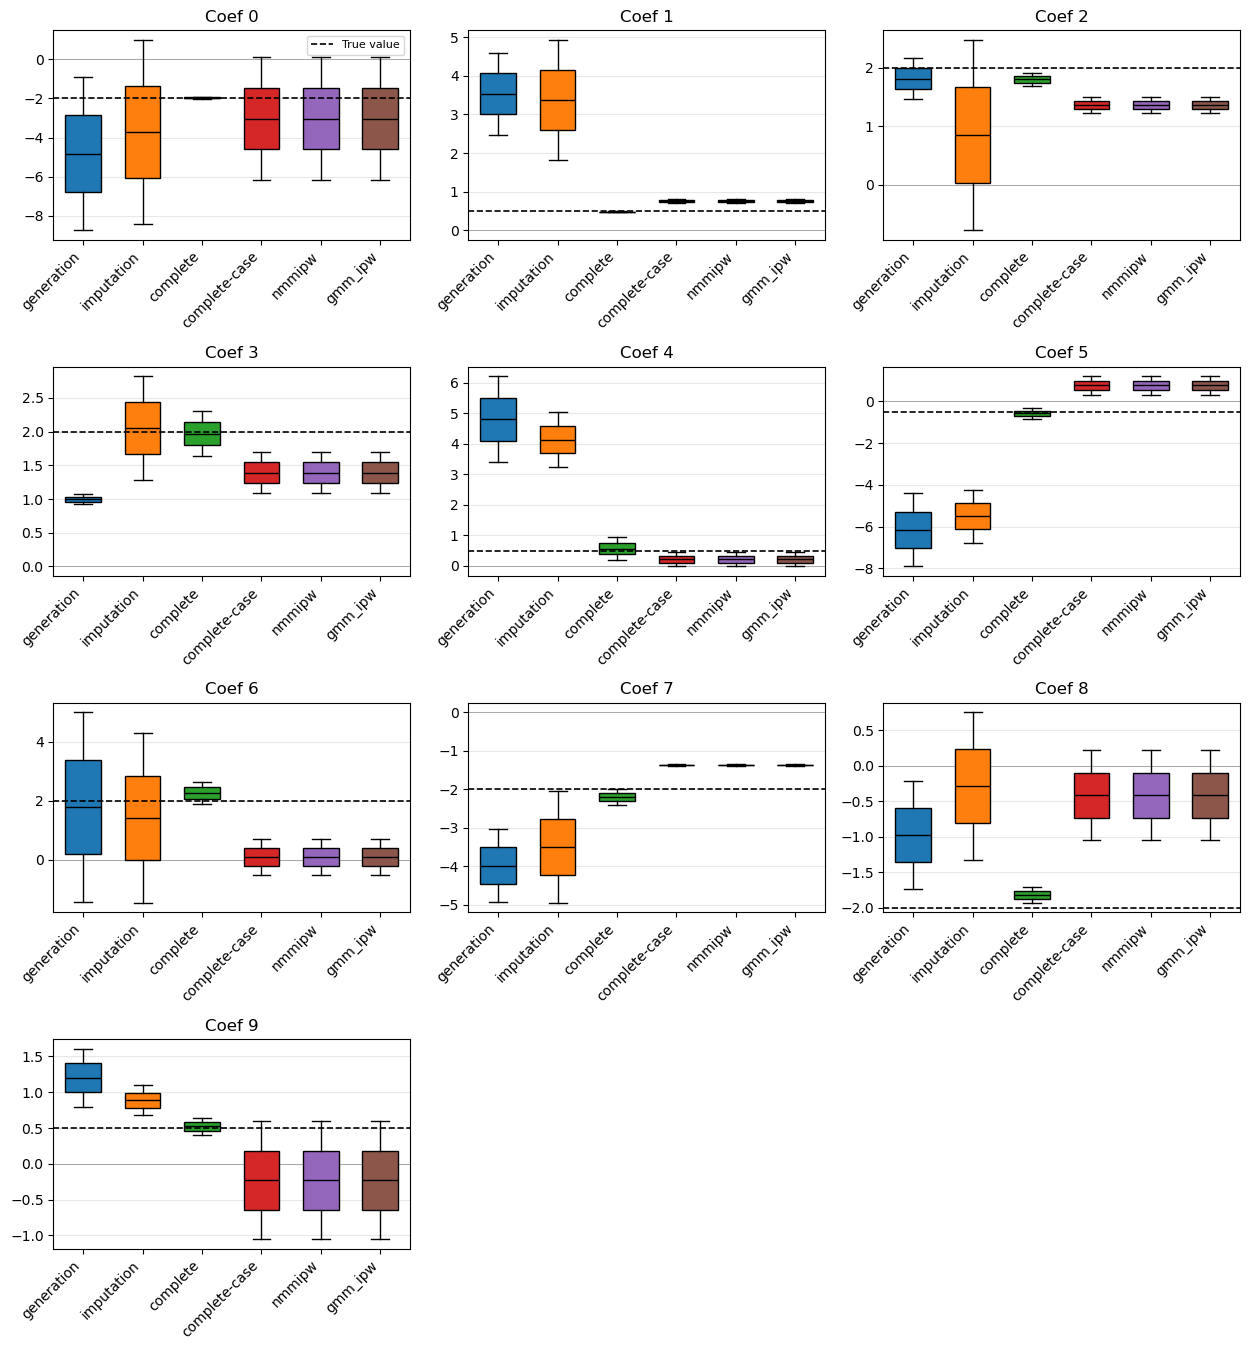

In [24]:
plot_coefficient_boxplots(coef_est, coef=coef_true)
# plt.savefig("coef.png")

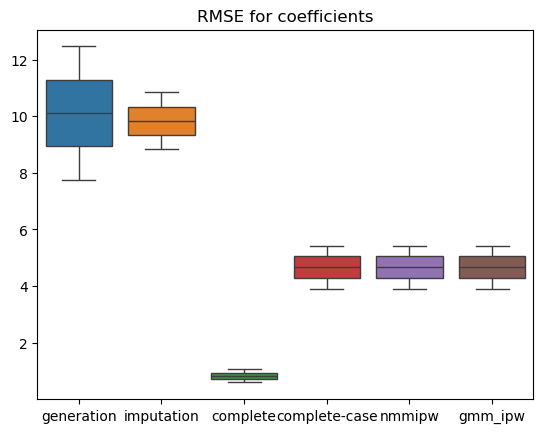

In [26]:
if coef_true != None:
    coef_true_np = coef_true.detach().numpy()
    rmse_coef = pd.DataFrame({method: [np.linalg.norm(c - coef_true_np) for c in coefs] for method, coefs in coef_est.items()})
    sns.boxplot(rmse_coef, showfliers=False)
    plt.title("RMSE for coefficients")
    # plt.savefig("rmse_coef.png")

Text(0.5, 1.0, 'RMSE on test data')

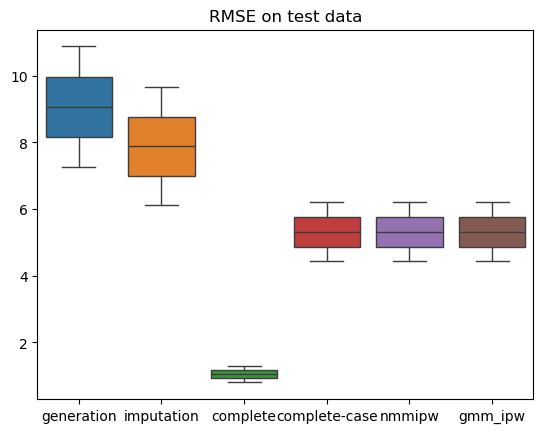

Fast method only supports Xtrain


In [27]:
rmse = np.sqrt(pd.DataFrame(mse))
sns.boxplot(rmse, showfliers=False)
plt.title("RMSE on test data")
# plt.savefig("rmse.png")